# Activation patching στο Qwen2.5-7B-Instruct με το `sarcasm_dataset.csv`



**Τι κάνουμε.** Τρέχουμε το μοντέλο σε μια μη σαρκαστική πρόταση (*corrupted*) και σε ένα σημείο (layer, θέση) βάζουμε
την εσωτερική κατάσταση από τη σαρκαστική (*clean* = S). Μετράμε πόσο γύρισε η απάντηση:

$$R = \frac{d_{\text{patched}} - d_{\text{corrupted}}}{d_{\text{clean}} - d_{\text{corrupted}}}, \qquad d = \text{logit(Yes)} - \text{logit(No)}$$

$R=1$: αυτό το σημείο μόνο του φέρνει πίσω όλον τον σαρκασμό. $R=0$: δεν παίζει ρόλο.

| πείραμα | clean | corrupted | τι αλλάζει |
|---|---|---|---|
| **αλλάζει η κατάσταση** | S | P | ευχάριστη → δυσάρεστη κατάσταση |
| **αλλάζει η φράση** | S | N | αρνητική → θετική φράση |

Μόνο τριάδες `discovery` που ταιριάζουν σε tokens, και μόνο ζεύγη όπου το μοντέλο απαντά σωστά ($d_\text{clean} - d_\text{corrupted} \ge 1$).

In [ ]:
%pip install -q -U accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.6 MB/s eta 0:00:00


## 1. Ρυθμίσεις και δεδομένα

In [ ]:
import gc, os, time, zipfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ΚΑΜΙΑ - άλλαξε runtime σε T4 GPU!")

MODEL_NAME, FOUR_BIT = "Qwen/Qwen2.5-7B-Instruct", True
N_PAIRS = 32        # ζεύγη ανά πείραμα
MIN_MARGIN = 1.0    # κρατάμε ζεύγη με d(clean) - d(corrupted) >= 1 (το μοντέλο απαντά σωστά)
SEED = 0
KINDS = ["resid", "attn", "mlp"]
KIND_NAMES = {"resid": "Residual stream", "attn": "Attention output", "mlp": "MLP output"}
REGIONS = ["κατάσταση", "φράση", "ερώτηση", "τελευταίο token"]
OUT_DIR = "patching_results"
os.makedirs(OUT_DIR, exist_ok=True)

CSV_PATH = "sarcasm_dataset.csv"
if not os.path.exists(CSV_PATH):
    from google.colab import files
    print("Ανέβασε το sarcasm_dataset.csv:")
    CSV_PATH = list(files.upload())[0]

df = pd.read_csv(CSV_PATH)
disc = df[df.split == "discovery"]
rows = {(r.triple_id, r.condition): r for r in disc.itertuples()}
tids = disc.triple_id.unique()
EXPERIMENTS = {
    "αλλάζει η κατάσταση": [(rows[(t, "S")], rows[(t, "P")]) for t in tids if rows[(t, "S")].token_matched_PS],
    "αλλάζει η φράση":     [(rows[(t, "S")], rows[(t, "N")]) for t in tids if rows[(t, "S")].token_matched_SN],
}
for k, v in EXPERIMENTS.items():
    print(f"{k:22s}: {len(v)} υποψήφια ζεύγη (discovery, ίδιο μήκος)")

GPU: Tesla T4
Ανέβασε το sarcasm_dataset.csv:


Saving sarcasm_dataset.csv to sarcasm_dataset.csv
αλλάζει η κατάσταση   : 116 υποψήφια ζεύγη (discovery, ίδιο μήκος)
αλλάζει η φράση       : 184 υποψήφια ζεύγη (discovery, ίδιο μήκος)


## 2. Φόρτωση μοντέλου

In [ ]:
t0 = time.time()
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
kw = dict(device_map="cuda", low_cpu_mem_usage=True)
if FOUR_BIT:
    kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
else:
    kw["torch_dtype"] = torch.float16
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **kw).eval()
N_LAYERS = len(model.model.layers)
T_LOAD = time.time() - t0
print(f"Φορτώθηκε σε {T_LOAD / 60:.1f} λεπτά, {N_LAYERS} layers")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Φορτώθηκε σε 3.8 λεπτά, 28 layers


## 3. Συναρτήσεις (prompt → tokens, hooks, patching)

In [ ]:
def build(row):
    """Prompt της γραμμής (με chat template) -> token ids + θέσεις κάθε περιοχής."""
    text = tok.apply_chat_template([{"role": "user", "content": row.prompt}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)
    enc = tok(text, add_special_tokens=False, return_offsets_mapping=True)
    ids, offs = enc["input_ids"], enc["offset_mapping"]
    u0 = text.index(row.text)
    s0 = u0 + row.text.index(row.situation); s1 = s0 + len(row.situation)
    f0 = u0 + row.text.index(row.frame);     f1 = f0 + len(row.frame)
    q1 = text.index("Answer with Yes or No.") + len("Answer with Yes or No.")
    toks = lambda a, b: [i for i, (x, y) in enumerate(offs) if y > a and x < b]
    frame_toks = toks(f0, f1)
    return ids, {"κατάσταση": toks(s0, s1), "φράση": frame_toks,
                 "ερώτηση": [i for i in toks(f1, q1) if i not in frame_toks],   # χωρίς επικάλυψη με τη φράση
                 "τελευταίο token": [len(ids) - 1]}


def aligned(a, b, allowed):
    return len(a) == len(b) and all(i in allowed for i, (x, y) in enumerate(zip(a, b)) if x != y)


def yn_ids():
    pick = lambda ws: [t[0] for t in (tok.encode(w, add_special_tokens=False) for w in ws) if len(t) == 1]
    return pick(["Yes", "yes"]), pick(["No", "no"])
Y_IDS, N_IDS = yn_ids()


def last_logits(x, **kw):
    try:
        out = model(x, logits_to_keep=1, **kw)
    except TypeError:
        out = model(x, **kw)
    return out, out.logits[:, -1, :]


def d_of(logits):
    lg = logits.float()
    return (torch.logsumexp(lg[:, Y_IDS], -1) - torch.logsumexp(lg[:, N_IDS], -1)).cpu()


@torch.no_grad()
def d_single(ids):
    return d_of(last_logits(torch.tensor([ids], device=model.device))[1])[0].item()


@torch.no_grad()
def run_clean(ids):
    """Clean τρέξιμο: κρατάμε residual (είσοδος κάθε layer), έξοδο attention και MLP."""
    cache, hooks = {}, []
    for l, layer in enumerate(model.model.layers):
        hooks.append(layer.self_attn.register_forward_hook(
            lambda m, a, o, l=l: cache.__setitem__(("attn", l), (o[0] if isinstance(o, tuple) else o).detach())))
        hooks.append(layer.mlp.register_forward_hook(lambda m, a, o, l=l: cache.__setitem__(("mlp", l), o.detach())))
    try:
        out, logits = last_logits(torch.tensor([ids], device=model.device), output_hidden_states=True)
    finally:
        for h in hooks:
            h.remove()
    for l in range(N_LAYERS):
        cache[("resid", l)] = out.hidden_states[l].detach()
    return d_of(logits)[0].item(), cache


@torch.no_grad()
def patch_sweep(corr_ids, cache, kind, pos_groups):
    """Για κάθε layer ένα batch· η γραμμή b αντικαθιστά τις θέσεις pos_groups[b] με την clean τιμή.
    Επιστρέφει d μετά την αντικατάσταση: [N_LAYERS, len(pos_groups)]."""
    x = torch.tensor([corr_ids] * len(pos_groups), device=model.device)
    res = []
    for l, layer in enumerate(model.model.layers):
        clean = cache[(kind, l)][0]

        def apply(t):
            t = t.clone()
            for b, pos in enumerate(pos_groups):
                t[b, pos] = clean[pos].to(t.dtype)
            return t

        if kind == "resid":
            def pre(m, args, kwargs):
                if args:
                    return (apply(args[0]),) + tuple(args[1:]), kwargs
                kwargs["hidden_states"] = apply(kwargs["hidden_states"])
                return args, kwargs
            h = layer.register_forward_pre_hook(pre, with_kwargs=True)
        else:
            mod = layer.self_attn if kind == "attn" else layer.mlp
            h = mod.register_forward_hook(lambda m, a, o: (apply(o[0]),) + tuple(o[1:]) if isinstance(o, tuple) else apply(o))
        try:
            res.append(d_of(last_logits(x)[1]))
        finally:
            h.remove()
    return torch.stack(res).numpy()

## 4. Επιλογή ζευγών

Για κάθε υποψήφιο ζεύγος: έλεγχος ότι ταιριάζει θέση προς θέση και ότι το μοντέλο απαντά σωστά. Κρατάμε τυχαία `N_PAIRS`.

In [ ]:
rng = np.random.default_rng(SEED)
SELECTED, pair_log = {}, []
for exp, cands in EXPERIMENTS.items():
    allowed_region = "κατάσταση" if "κατάσταση" in exp else "φράση"
    order = rng.permutation(len(cands))
    chosen, checked, wrong = [], 0, 0
    for i in order:
        S_row, C_row = cands[i]
        S, reg = build(S_row)
        C, _ = build(C_row)
        if not aligned(S, C, set(reg[allowed_region])):
            continue
        checked += 1
        dS, dC = d_single(S), d_single(C)
        ok = dS - dC >= MIN_MARGIN
        wrong += not ok
        pair_log.append(dict(experiment=exp, triple_id=S_row.triple_id, clean_text=S_row.text, corrupted_text=C_row.text,
                             d_clean=round(dS, 3), d_corrupted=round(dC, 3), passes_margin=ok, used=False))
        if ok:
            chosen.append((S, C, reg, len(pair_log) - 1))
            if len(chosen) == N_PAIRS:
                break
    for *_, j in chosen:
        pair_log[j]["used"] = True
    SELECTED[exp] = chosen
    print(f"{exp:22s}: ελέγχθηκαν {checked}, λάθος απάντηση {wrong}, κρατήθηκαν {len(chosen)}")

pairs_df = pd.DataFrame(pair_log)
pairs_df.to_csv(f"{OUT_DIR}/pairs_used.csv", index=False)

S, C, reg, _ = SELECTED["αλλάζει η κατάσταση"][0]
print("\nΠεριοχές σε ένα παράδειγμα:")
for r in REGIONS:
    print(f"  {r:16s} -> {[tok.decode([S[p]]) for p in reg[r]]}")

αλλάζει η κατάσταση   : ελέγχθηκαν 34, λάθος απάντηση 2, κρατήθηκαν 32
αλλάζει η φράση       : ελέγχθηκαν 38, λάθος απάντηση 6, κρατήθηκαν 32

Περιοχές σε ένα παράδειγμα:
  κατάσταση        -> [' a', ' bad', ' grade']
  φράση            -> [' I', "'m", ' so', ' lucky', '."\n']
  ερώτηση          -> ['Is', ' this', ' person', ' being', ' sarcast', 'ic', '?', ' Answer', ' with', ' Yes', ' or', ' No', '.']
  τελευταίο token  -> ['\n']


## 5. Patching: layer × περιοχή για residual / attention / MLP (το κύριο πείραμα)

In [ ]:
t1 = time.time()
RESULTS = {}   # exp -> kind -> πίνακας [ζεύγη, layers, περιοχές]
for exp, chosen in SELECTED.items():
    RESULTS[exp] = {k: [] for k in KINDS}
    for n, (S, C, reg, _) in enumerate(chosen):
        d_clean, cache = run_clean(S)
        d_corr = d_single(C)
        groups = [reg[r] for r in REGIONS]
        for kind in KINDS:
            d = patch_sweep(C, cache, kind, groups)
            RESULTS[exp][kind].append((d - d_corr) / (d_clean - d_corr))
        del cache
        torch.cuda.empty_cache()
        if (n + 1) % 8 == 0:
            print(f"  {exp}: {n + 1}/{len(chosen)} ζεύγη ({(time.time() - t1) / 60:.1f} λ.)")
    RESULTS[exp] = {k: np.stack(v) for k, v in RESULTS[exp].items()}
T_MAIN = time.time() - t1

long = []
for exp, by_kind in RESULTS.items():
    for kind, A in by_kind.items():
        mean, se = A.mean(0), A.std(0, ddof=1) / np.sqrt(len(A))
        for l in range(N_LAYERS):
            for j, r in enumerate(REGIONS):
                long.append(dict(experiment=exp, kind=kind, layer=l, region=r,
                                 mean_R=round(float(mean[l, j]), 4), se_R=round(float(se[l, j]), 4), n_pairs=len(A)))
pd.DataFrame(long).to_csv(f"{OUT_DIR}/patching_results.csv", index=False)
print(f"Έτοιμο σε {T_MAIN / 60:.1f} λεπτά")

  αλλάζει η κατάσταση: 8/32 ζεύγη (4.2 λ.)
  αλλάζει η κατάσταση: 16/32 ζεύγη (8.3 λ.)
  αλλάζει η κατάσταση: 24/32 ζεύγη (12.5 λ.)
  αλλάζει η κατάσταση: 32/32 ζεύγη (16.7 λ.)
  αλλάζει η φράση: 8/32 ζεύγη (20.9 λ.)
  αλλάζει η φράση: 16/32 ζεύγη (25.1 λ.)
  αλλάζει η φράση: 24/32 ζεύγη (29.2 λ.)
  αλλάζει η φράση: 32/32 ζεύγη (33.4 λ.)
Έτοιμο σε 33.4 λεπτά


### 5α. Layer × περιοχή

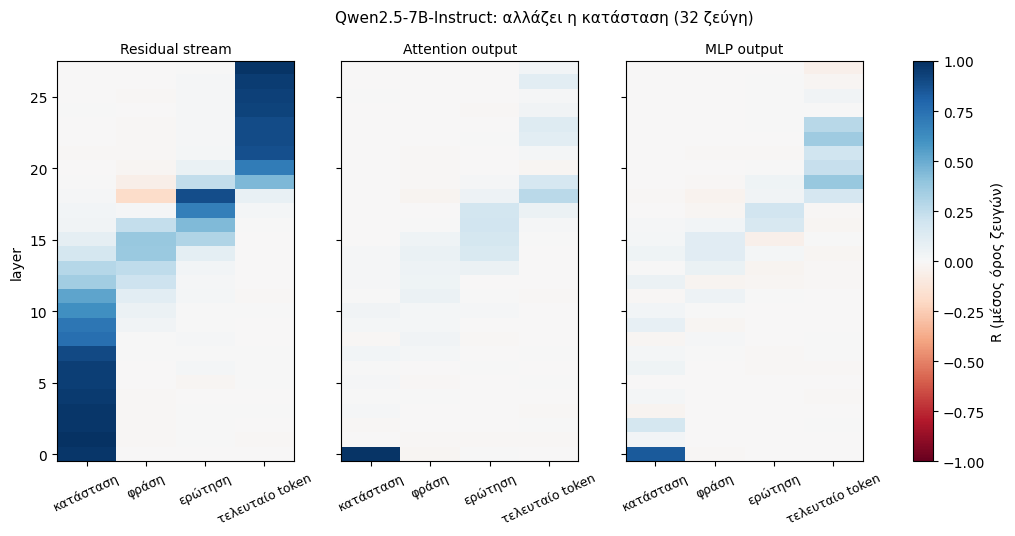

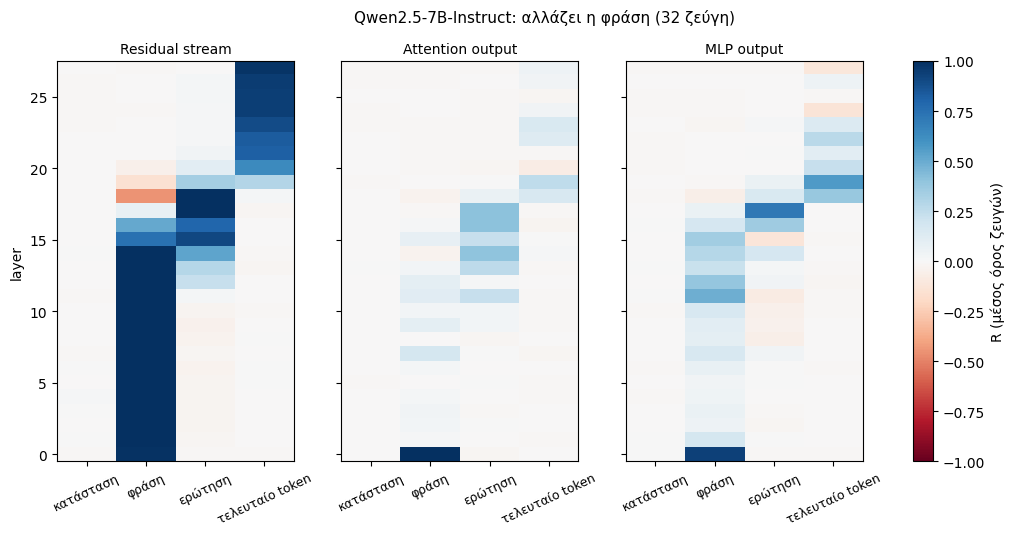

In [ ]:
for i, (exp, by_kind) in enumerate(RESULTS.items()):
    fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), sharey=True)
    for ax, kind in zip(axes, KINDS):
        im = ax.imshow(by_kind[kind].mean(0), aspect="auto", cmap="RdBu", vmin=-1, vmax=1, origin="lower")
        ax.set_xticks(range(len(REGIONS))); ax.set_xticklabels(REGIONS, rotation=25, fontsize=9)
        ax.set_title(KIND_NAMES[kind], fontsize=10)
    axes[0].set_ylabel("layer")
    n = len(by_kind["resid"])
    fig.suptitle(f"Qwen2.5-7B-Instruct: {exp} ({n} ζεύγη)", fontsize=11)
    plt.colorbar(im, ax=axes, label="R (μέσος όρος ζευγών)")
    plt.savefig(f"{OUT_DIR}/fig_regions_{'situation' if 'κατάσταση' in exp else 'frame'}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 5β. Η «σκάλα» ως καμπύλες: R του residual ανά layer, για κάθε περιοχή

Η σκιά είναι διάστημα 95% (±1.96 τυπικά σφάλματα πάνω στα ζεύγη). Εδώ φαίνεται καθαρά σε ποιο layer η πληροφορία φεύγει από τη μία περιοχή και πάει στην επόμενη.

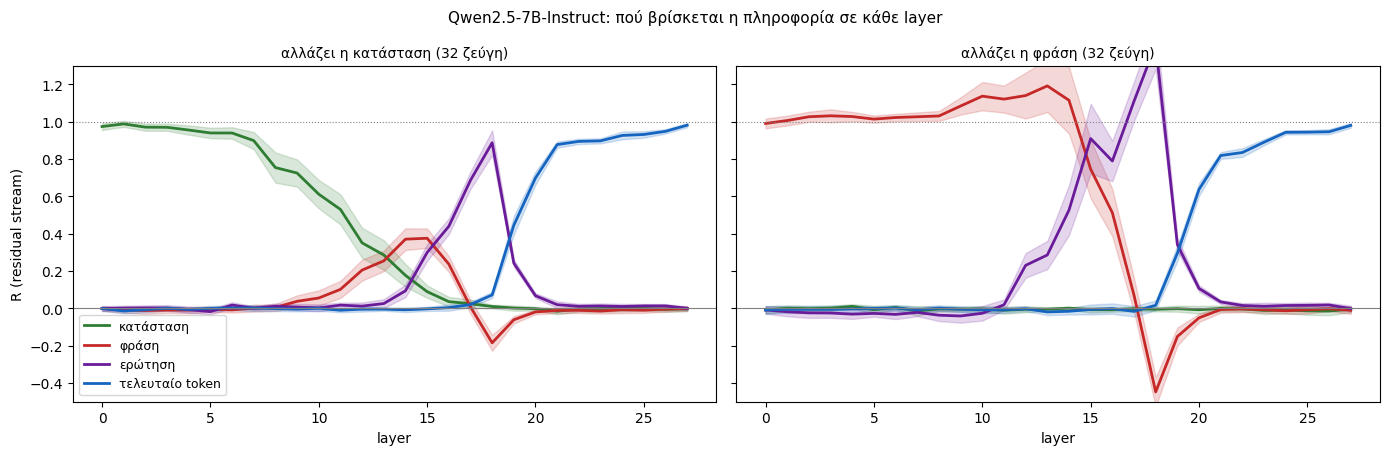

αλλάζει η κατάσταση   : το τελευταίο token ξεπερνά R=0.5 στο layer 20
αλλάζει η φράση       : το τελευταίο token ξεπερνά R=0.5 στο layer 20


In [ ]:
cols = {"κατάσταση": "#2e7d32", "φράση": "#c62828", "ερώτηση": "#6a1b9a", "τελευταίο token": "#1565c0"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (exp, by_kind) in zip(axes, RESULTS.items()):
    A = by_kind["resid"]
    mean, se = A.mean(0), A.std(0, ddof=1) / np.sqrt(len(A))
    L = np.arange(N_LAYERS)
    for j, r in enumerate(REGIONS):
        ax.plot(L, mean[:, j], color=cols[r], lw=2, label=r)
        ax.fill_between(L, mean[:, j] - 1.96 * se[:, j], mean[:, j] + 1.96 * se[:, j], color=cols[r], alpha=0.18)
    ax.axhline(0, c="gray", lw=0.8); ax.axhline(1, c="gray", lw=0.8, ls=":")
    ax.set_ylim(-0.5, 1.3); ax.set_xlabel("layer"); ax.set_title(f"{exp} ({len(A)} ζεύγη)", fontsize=10)
axes[0].set_ylabel("R (residual stream)"); axes[0].legend(fontsize=9)
plt.suptitle("Qwen2.5-7B-Instruct: πού βρίσκεται η πληροφορία σε κάθε layer", fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_curves.png", dpi=150); plt.show()

for exp, by_kind in RESULTS.items():
    last = by_kind["resid"].mean(0)[:, REGIONS.index("τελευταίο token")]
    l50 = int(np.argmax(last >= 0.5)) if (last >= 0.5).any() else None
    print(f"{exp:22s}: το τελευταίο token ξεπερνά R=0.5 στο layer {l50}")

## 6. Ένα παράδειγμα: layer × token (όπως στο ARENA)

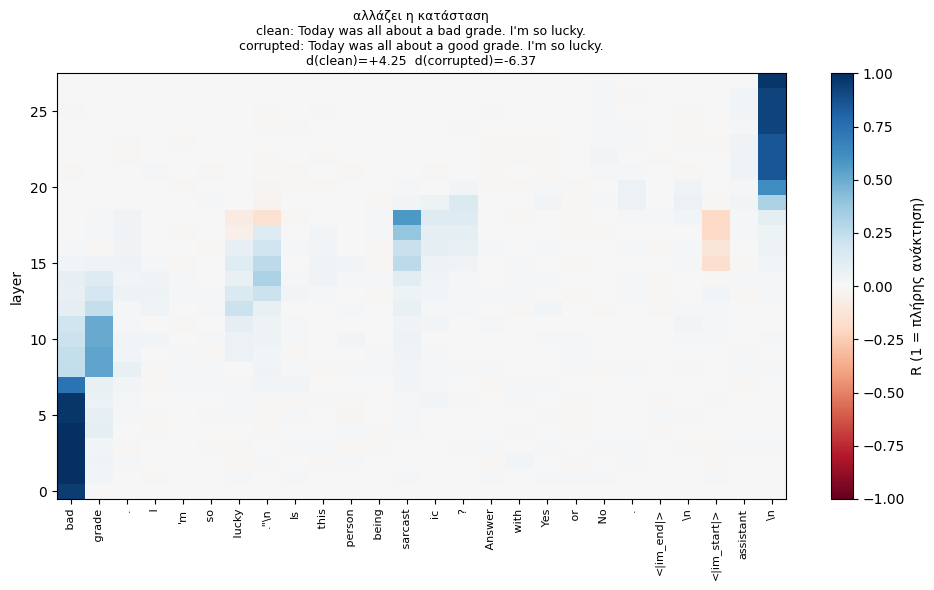

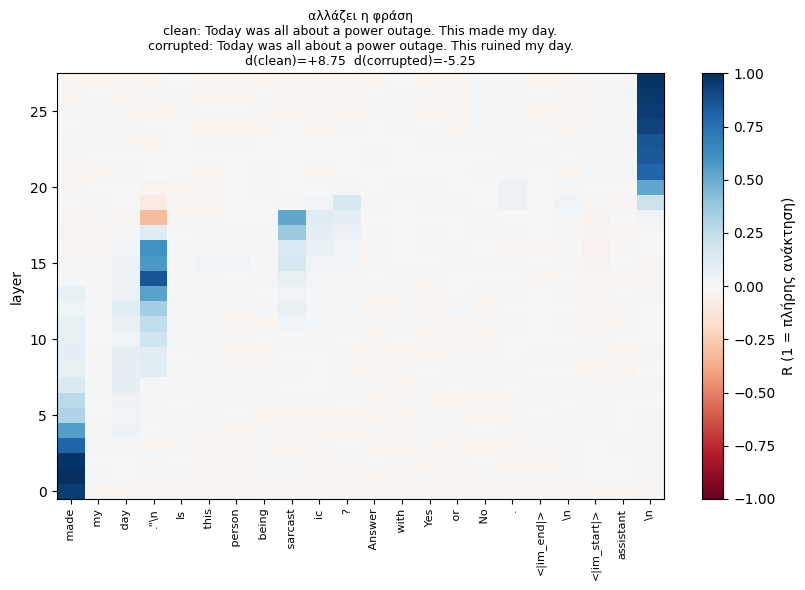

In [ ]:
t2 = time.time()
for exp, chosen in SELECTED.items():
    S, C, reg, j = chosen[0]
    d_clean, cache = run_clean(S)
    d_corr = d_single(C)
    first = min(i for i, (a, b) in enumerate(zip(S, C)) if a != b)
    positions = list(range(first, len(S)))
    d = patch_sweep(C, cache, "resid", [[p] for p in positions])
    R = (d - d_corr) / (d_clean - d_corr)
    del cache; torch.cuda.empty_cache()
    labels = [repr(tok.decode([S[p]]))[1:-1][:12] for p in positions]
    fig, ax = plt.subplots(figsize=(max(8, len(positions) * 0.38), 6))
    im = ax.imshow(R, aspect="auto", cmap="RdBu", vmin=-1, vmax=1, origin="lower")
    ax.set_xticks(range(len(positions))); ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_ylabel("layer")
    ax.set_title(f"{exp}\nclean: {pairs_df.loc[j, 'clean_text']}\ncorrupted: {pairs_df.loc[j, 'corrupted_text']}\n"
                 f"d(clean)={d_clean:+.2f}  d(corrupted)={d_corr:+.2f}", fontsize=9)
    plt.colorbar(im, ax=ax, label="R (1 = πλήρης ανάκτηση)")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig_example_{'situation' if 'κατάσταση' in exp else 'frame'}.png", dpi=150)
    plt.show()
T_EX = time.time() - t2

## 7. Χρόνοι και κατέβασμα

In [ ]:
timing = pd.DataFrame([dict(model=MODEL_NAME, gpu=torch.cuda.get_device_name(0), load_min=round(T_LOAD / 60, 1),
                            main_experiment_min=round(T_MAIN / 60, 1), examples_min=round(T_EX / 60, 1),
                            pairs_per_experiment=N_PAIRS)])
timing.to_csv(f"{OUT_DIR}/timing.csv", index=False)
print(timing.T.to_string(header=False))

zip_path = "patching_results.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for f in sorted(os.listdir(OUT_DIR)):
        z.write(os.path.join(OUT_DIR, f), f)
print("\nΑρχεία:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Εκτός Colab: τα αρχεία είναι στο", zip_path)

model                 Qwen/Qwen2.5-7B-Instruct
gpu                                   Tesla T4
load_min                                   3.8
main_experiment_min                       33.4
examples_min                               1.3
pairs_per_experiment                        32

Αρχεία: ['fig_curves.png', 'fig_example_frame.png', 'fig_example_situation.png', 'fig_regions_frame.png', 'fig_regions_situation.png', 'pairs_used.csv', 'patching_results.csv', 'timing.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>